In [2]:
import io
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

uploaded = files.upload()
file_name = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[file_name]))

print("Loaded file:", file_name, "| Shape:", df.shape)
print("Columns:", list(df.columns))
display(df.head())

Saving traffic_dataset.csv to traffic_dataset (1).csv
Loaded file: traffic_dataset (1).csv | Shape: (10000, 7)
Columns: ['Unnamed: 0', 'vehicle_count', 'average_speed', 'lane_occupancy', 'flow_rate', 'time_of_day', 'waiting_time']


,Unnamed: 0,vehicle_count,average_speed,lane_occupancy,flow_rate,time_of_day,waiting_time
0,0,54,10.216100,59.920218,1467,evening,12.524458
1,1,75,63.642160,87.634821,1098,afternoon,44.828142
2,2,95,37.380760,0.765823,1411,night,80.438426
3,3,87,59.812086,75.961246,892,evening,11.263687
4,4,38,48.431821,43.528478,949,night,18.141549


In [10]:
cols_lower = {c.lower().strip(): c for c in df.columns}

def find_col(candidates):
    for cand in candidates:
        for low_c, orig_c in cols_lower.items():
            if cand in low_c:
                return orig_c
    return None

count_col = find_col(["vehicle_count", "count", "flow_rate", "flow", "volume", "vehicles", "traffic"])
speed_col = find_col(["average_speed", "speed", "avg_speed", "velocity"])
occ_col   = find_col(["lane_occupancy", "occupancy", "density"])
wait_col  = find_col(["waiting_time", "wait", "delay", "queue"])
time_col  = find_col(["time_of_day", "time", "period", "hour", "timestamp", "date"])

print("Detected columns ->",
      "count:", count_col, "| speed:", speed_col,
      "| occupancy:", occ_col, "| waiting:", wait_col, "| time:", time_col)

T = 6
num_phases = 2

numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
primary_col = count_col if count_col in numeric_cols else (numeric_cols[0] if numeric_cols else None)
assert primary_col is not None, "No numeric traffic column found—please check df.columns!"

clean_df = df.dropna(subset=[primary_col]).reset_index(drop=True)

series = clean_df[primary_col].astype(float).values
best_start, best_span = 0, -1.0
for i in range(max(1, len(series) - T + 1)):
    chunk = series[i:i+T]
    if len(chunk) == T:
        span = float(chunk.max() - chunk.min())
        if span > best_span:
            best_span = span
            best_start = i

window = clean_df.iloc[best_start:best_start+T].reset_index(drop=True)
raw_vals = window[primary_col].astype(float).values

max_v = max(float(np.max(raw_vals)), 1.0)
min_v = float(np.min(raw_vals))
p0 = np.clip(np.round((raw_vals / max_v) * 10.0), 1.0, 12.0)
p1 = np.clip(np.round(((max_v - raw_vals + min_v) / max_v) * 8.0), 1.0, 12.0)
arrivals = np.vstack([p0, p1])

avg_speed = float(window[speed_col].mean()) if (speed_col and speed_col in numeric_cols) else 35.0

print("\nSelected traffic window:")
preview_cols = [c for c in [time_col, primary_col, speed_col, occ_col, wait_col] if c is not None]
print(window[preview_cols])
print("\nPhase 0 arrivals per step:", arrivals[0])
print("Phase 1 arrivals per step:", arrivals[1])
print(f"Mean Speed context: {avg_speed:.1f}")

Detected columns -> count: vehicle_count | speed: average_speed | occupancy: lane_occupancy | waiting: waiting_time | time: time_of_day

Selected traffic window:
  time_of_day  vehicle_count  average_speed  lane_occupancy  waiting_time
0   afternoon            137      62.081160       11.587658      2.301653
1       night             76      51.249694       90.170187     23.720751
2     evening             37      51.751219       15.499543     25.322918
3       night             31      45.545405       30.441880      0.332295
4     evening            119      41.304281       79.045017     32.074595
5     morning             13      30.019614       80.634697     43.231960

Phase 0 arrivals per step: [10.  6.  3.  2.  9.  1.]
Phase 1 arrivals per step: [1. 4. 7. 7. 2. 8.]
Mean Speed context: 47.0


In [11]:
departure_rate = max(6.0, float(np.median(arrivals)))
fixed_schedule = [t % num_phases for t in range(T)]

def simulate_intersection(schedule, arrivals_mat, dep_rate=6.0, speed_val=35.0):
    queues = np.zeros(num_phases, dtype=float)
    total_delay = 0.0
    switches = 0
    prev_phase = None

    for t in range(len(schedule)):
        p = schedule[t]
        if prev_phase is not None and p != prev_phase:
            switches += 1
        prev_phase = p

        queues += arrivals_mat[:, t]
        served = min(queues[p], dep_rate)
        queues[p] -= served
        total_delay += np.sum(queues)

    speed_factor = np.clip(40.0 / max(speed_val, 10.0), 0.7, 1.5)
    co2_proxy_g = (12.0 * speed_factor) * total_delay + 18.0 * switches

    return {
        "schedule": schedule,
        "delay": float(total_delay),
        "switches": int(switches),
        "co2_g": float(co2_proxy_g),
        "remaining_queue": float(np.sum(queues))
    }

baseline_res = simulate_intersection(fixed_schedule, arrivals, departure_rate, avg_speed)

w1 = 1.0
w2 = 3.5
lam = 50.0

best_energy = float("inf")
best_schedule = None
best_sim = None

for cand in itertools.product(range(num_phases), repeat=T):
    sim = simulate_intersection(list(cand), arrivals, departure_rate, avg_speed)
    one_hot_penalty = 0.0
    energy = w1 * sim["delay"] + w2 * sim["switches"] + lam * one_hot_penalty
    if energy < best_energy:
        best_energy = energy
        best_schedule = list(cand)
        best_sim = sim

print("Fixed-Cycle Schedule :", baseline_res["schedule"], "-> Delay:", round(baseline_res["delay"], 1))
print("Optimal QUBO Schedule:", best_schedule,          "-> Delay:", round(best_sim["delay"], 1))
print("QUBO Objective Energy:", round(best_energy, 2))

Fixed-Cycle Schedule : [0, 1, 0, 1, 0, 1] -> Delay: 93.0
Optimal QUBO Schedule: [0, 0, 0, 1, 1, 1] -> Delay: 88.0
QUBO Objective Energy: 91.5


Delay Reduction   : 5.4%
Est. CO2 Reduction: 11.8%


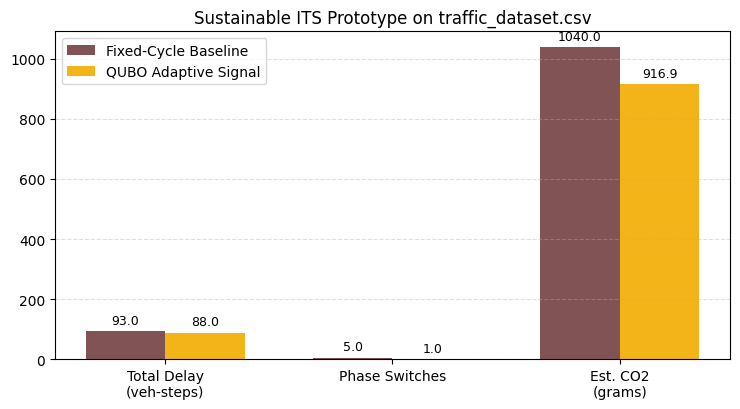

In [12]:
delay_red = (baseline_res["delay"] - best_sim["delay"]) / max(baseline_res["delay"], 1e-6) * 100
co2_red   = (baseline_res["co2_g"] - best_sim["co2_g"]) / max(baseline_res["co2_g"], 1e-6) * 100

print(f"Delay Reduction   : {delay_red:.1f}%")
print(f"Est. CO2 Reduction: {co2_red:.1f}%")

labels = ["Total Delay\n(veh-steps)", "Phase Switches", "Est. CO2\n(grams)"]
base_vals = [baseline_res["delay"], baseline_res["switches"], baseline_res["co2_g"]]
qubo_vals = [best_sim["delay"], best_sim["switches"], best_sim["co2_g"]]

x = np.arange(len(labels))
w = 0.35

fig, ax = plt.subplots(figsize=(7.5, 4.2))
b1 = ax.bar(x - w/2, base_vals, w, label="Fixed-Cycle Baseline", color="#815355")
b2 = ax.bar(x + w/2, qubo_vals, w, label="QUBO Adaptive Signal", color="#F2B418")

ax.set_title("Sustainable ITS Prototype on traffic_dataset.csv")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.4)

for bars in (b1, b2):
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f"{h:.1f}",
                    xy=(bar.get_x() + bar.get_width() / 2, h),
                    xytext=(0, 3), textcoords="offset points",
                    ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()

Simulated Annealing Schedule : [0, 0, 1, 1, 1, 1] | Delay: 88.0 | Time: 50.94 ms
Matches Exact Best Energy    : True
PennyLane check skipped (ModuleNotFoundError); SA + exact QUBO active.


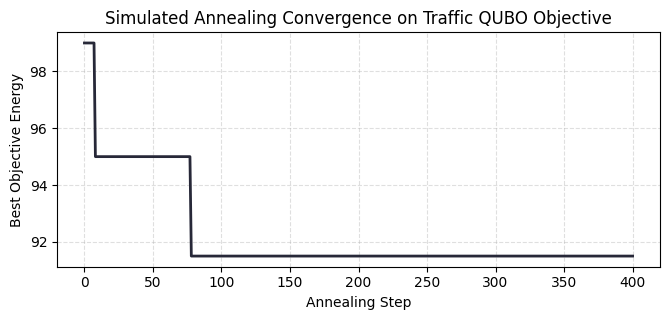

In [13]:
import time

def simulated_annealing_qubo(arrivals_mat, dep_rate, speed_val, w1=1.0, w2=3.5, steps=400, t_start=12.0, t_end=0.2):
    start_t = time.perf_counter()
    curr_sched = [np.random.randint(0, num_phases) for _ in range(T)]
    curr_sim = simulate_intersection(curr_sched, arrivals_mat, dep_rate, speed_val)
    curr_e = w1 * curr_sim["delay"] + w2 * curr_sim["switches"]

    best_sched = list(curr_sched)
    best_sim = curr_sim
    best_e = curr_e
    energy_history = [curr_e]

    for step in range(steps):
        frac = step / max(steps - 1, 1)
        temp = t_start * ((t_end / t_start) ** frac)

        cand_sched = list(curr_sched)
        idx = np.random.randint(0, T)
        cand_sched[idx] = 1 - cand_sched[idx]

        cand_sim = simulate_intersection(cand_sched, arrivals_mat, dep_rate, speed_val)
        cand_e = w1 * cand_sim["delay"] + w2 * cand_sim["switches"]

        delta = cand_e - curr_e
        if delta <= 0 or np.random.rand() < np.exp(-delta / max(temp, 1e-6)):
            curr_sched = cand_sched
            curr_sim = cand_sim
            curr_e = cand_e
            if curr_e < best_e:
                best_e = curr_e
                best_sched = list(curr_sched)
                best_sim = cand_sim

        energy_history.append(best_e)

    elapsed_ms = (time.perf_counter() - start_t) * 1000.0
    return best_sched, best_sim, best_e, elapsed_ms, energy_history

sa_sched, sa_sim, sa_energy, sa_ms, sa_hist = simulated_annealing_qubo(
    arrivals, departure_rate, avg_speed, w1=w1, w2=w2
)

qaoa_msg = "Optional PennyLane not installed (SA + exact QUBO reference active)."
try:
    import pennylane as qml
    dev = qml.device("default.qubit", wires=T)

    @qml.qnode(dev)
    def qaoa_circuit(params):
        gamma, beta = params[0], params[1]
        for w in range(T):
            qml.Hadamard(wires=w)
            qml.RZ(2.0 * gamma * (arrivals[0, w] - arrivals[1, w]) / max_v, wires=w)
            qml.RX(2.0 * beta, wires=w)
        return [qml.expval(qml.PauliZ(w)) for w in range(T)]

    res_z = qaoa_circuit([0.4, 0.3])
    qaoa_sched = [0 if z >= 0 else 1 for z in res_z]
    qaoa_sim = simulate_intersection(qaoa_sched, arrivals, departure_rate, avg_speed)
    qaoa_msg = f"PennyLane QAOA sample schedule: {qaoa_sched} | Delay: {qaoa_sim['delay']:.1f}"
except Exception as e:
    qaoa_msg = f"PennyLane check skipped ({type(e).__name__}); SA + exact QUBO active."

print(f"Simulated Annealing Schedule : {sa_sched} | Delay: {sa_sim['delay']:.1f} | Time: {sa_ms:.2f} ms")
print(f"Matches Exact Best Energy    : {np.isclose(sa_energy, best_energy)}")
print(qaoa_msg)

plt.figure(figsize=(6.8, 3.3))
plt.plot(sa_hist, color="#272838", linewidth=2)
plt.title("Simulated Annealing Convergence on Traffic QUBO Objective")
plt.xlabel("Annealing Step")
plt.ylabel("Best Objective Energy")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Simulated Annealing Schedule : [0, 0, 1, 1, 1, 1] | Delay: 88.0 | Time: 19.83 ms
Matches Exact Best Energy    : True
PennyLane check skipped (ModuleNotFoundError); SA + exact QUBO active.


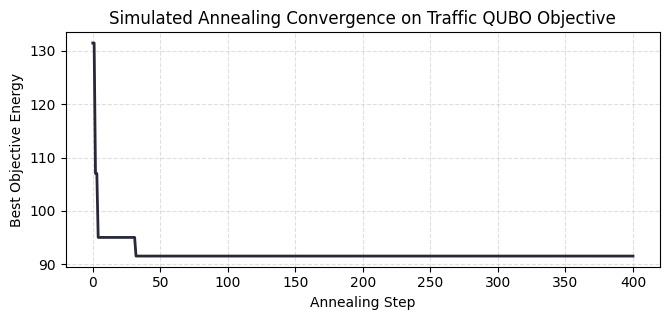

In [14]:
import time

def simulated_annealing_qubo(arrivals_mat, dep_rate, speed_val, w1=1.0, w2=3.5, steps=400, t_start=12.0, t_end=0.2):
    start_t = time.perf_counter()
    curr_sched = [np.random.randint(0, num_phases) for _ in range(T)]
    curr_sim = simulate_intersection(curr_sched, arrivals_mat, dep_rate, speed_val)
    curr_e = w1 * curr_sim["delay"] + w2 * curr_sim["switches"]

    best_sched = list(curr_sched)
    best_sim = curr_sim
    best_e = curr_e
    energy_history = [curr_e]

    for step in range(steps):
        frac = step / max(steps - 1, 1)
        temp = t_start * ((t_end / t_start) ** frac)

        cand_sched = list(curr_sched)
        idx = np.random.randint(0, T)
        cand_sched[idx] = 1 - cand_sched[idx]

        cand_sim = simulate_intersection(cand_sched, arrivals_mat, dep_rate, speed_val)
        cand_e = w1 * cand_sim["delay"] + w2 * cand_sim["switches"]

        delta = cand_e - curr_e
        if delta <= 0 or np.random.rand() < np.exp(-delta / max(temp, 1e-6)):
            curr_sched = cand_sched
            curr_sim = cand_sim
            curr_e = cand_e
            if curr_e < best_e:
                best_e = curr_e
                best_sched = list(curr_sched)
                best_sim = cand_sim

        energy_history.append(best_e)

    elapsed_ms = (time.perf_counter() - start_t) * 1000.0
    return best_sched, best_sim, best_e, elapsed_ms, energy_history

sa_sched, sa_sim, sa_energy, sa_ms, sa_hist = simulated_annealing_qubo(
    arrivals, departure_rate, avg_speed, w1=w1, w2=w2
)

qaoa_msg = "Optional PennyLane not installed (SA + exact QUBO reference active)."
try:
    import pennylane as qml
    dev = qml.device("default.qubit", wires=T)

    @qml.qnode(dev)
    def qaoa_circuit(params):
        gamma, beta = params[0], params[1]
        for w in range(T):
            qml.Hadamard(wires=w)
            qml.RZ(2.0 * gamma * (arrivals[0, w] - arrivals[1, w]) / max_v, wires=w)
            qml.RX(2.0 * beta, wires=w)
        return [qml.expval(qml.PauliZ(w)) for w in range(T)]

    res_z = qaoa_circuit([0.4, 0.3])
    qaoa_sched = [0 if z >= 0 else 1 for z in res_z]
    qaoa_sim = simulate_intersection(qaoa_sched, arrivals, departure_rate, avg_speed)
    qaoa_msg = f"PennyLane QAOA sample schedule: {qaoa_sched} | Delay: {qaoa_sim['delay']:.1f}"
except Exception as e:
    qaoa_msg = f"PennyLane check skipped ({type(e).__name__}); SA + exact QUBO active."

print(f"Simulated Annealing Schedule : {sa_sched} | Delay: {sa_sim['delay']:.1f} | Time: {sa_ms:.2f} ms")
print(f"Matches Exact Best Energy    : {np.isclose(sa_energy, best_energy)}")
print(qaoa_msg)

plt.figure(figsize=(6.8, 3.3))
plt.plot(sa_hist, color="#272838", linewidth=2)
plt.title("Simulated Annealing Convergence on Traffic QUBO Objective")
plt.xlabel("Annealing Step")
plt.ylabel("Best Objective Energy")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [15]:
co2_saved_g = max(0.0, baseline_res["co2_g"] - best_sim["co2_g"])
delta_e_traffic_kwh = co2_saved_g * 0.00042

e_qc_sim_kwh = 0.00005
delta_e_net_kwh = delta_e_traffic_kwh - e_qc_sim_kwh

print("=== SUSTAINABILITY ACCOUNTING (DEMO PROXY) ===")
print(f"Estimated CO2 Saved          : {co2_saved_g:.2f} g")
print(f"Traffic Energy Savings Proxy : {delta_e_traffic_kwh:.6f} kWh")
print(f"Compute Energy Proxy         : {e_qc_sim_kwh:.6f} kWh")
print(f"Net Energy Proxy (Delta E_net) : {delta_e_net_kwh:.6f} kWh")

for test_w2 in [0.5, 3.5, 8.0]:
    best_e_t, best_s_t = float("inf"), None
    for cand in itertools.product(range(num_phases), repeat=T):
        sim_t = simulate_intersection(list(cand), arrivals, departure_rate, avg_speed)
        e_t = w1 * sim_t["delay"] + test_w2 * sim_t["switches"]
        if e_t < best_e_t:
            best_e_t, best_s_t = e_t, sim_t
    print(f"w2={test_w2:4.1f} -> Schedule: {best_s_t['schedule']} | Delay: {best_s_t['delay']:.1f} | Switches: {best_s_t['switches']}")

=== SUSTAINABILITY ACCOUNTING (DEMO PROXY) ===
Estimated CO2 Saved          : 123.07 g
Traffic Energy Savings Proxy : 0.051691 kWh
Compute Energy Proxy         : 0.000050 kWh
Net Energy Proxy (Delta E_net) : 0.051641 kWh
w2= 0.5 -> Schedule: [0, 0, 0, 1, 1, 1] | Delay: 88.0 | Switches: 1
w2= 3.5 -> Schedule: [0, 0, 0, 1, 1, 1] | Delay: 88.0 | Switches: 1
w2= 8.0 -> Schedule: [0, 0, 0, 1, 1, 1] | Delay: 88.0 | Switches: 1


In [16]:
def evaluate_prototype_metrics(num_seeds=15, num_windows=3, target_confidence=0.99):
    window_starts = np.linspace(0, max(0, len(clean_df) - T), num_windows, dtype=int)
    records = []

    for w_idx, s_idx in enumerate(window_starts):
        sub = clean_df.iloc[s_idx:s_idx+T].reset_index(drop=True)
        vals = sub[primary_col].astype(float).values
        mv = max(float(np.max(vals)), 1.0)
        lv = float(np.min(vals))

        a_mat = np.vstack([
            np.clip(np.round((vals / mv) * 10.0), 1.0, 12.0),
            np.clip(np.round(((mv - vals + lv) / mv) * 8.0), 1.0, 12.0),
        ])
        dep = max(6.0, float(np.median(a_mat)))
        spd = float(sub[speed_col].mean()) if (speed_col and speed_col in numeric_cols) else avg_speed

        base_sim = simulate_intersection([t % num_phases for t in range(T)], a_mat, dep, spd)

        exact_energy = float("inf")
        exact_sim = None
        for cand in itertools.product(range(num_phases), repeat=T):
            sim_c = simulate_intersection(list(cand), a_mat, dep, spd)
            e_c = w1 * sim_c["delay"] + w2 * sim_c["switches"]
            if e_c < exact_energy:
                exact_energy = e_c
                exact_sim = sim_c

        sa_energies, sa_times_ms, sa_delays, sa_co2s = [], [], [], []
        hits = 0
        for seed in range(num_seeds):
            np.random.seed(seed)
            _, sim_sa, e_sa, ms_sa, _ = simulated_annealing_qubo(
                a_mat, dep, spd, w1=w1, w2=w2, steps=300
            )
            sa_energies.append(e_sa)
            sa_times_ms.append(ms_sa)
            sa_delays.append(sim_sa["delay"])
            sa_co2s.append(sim_sa["co2_g"])
            if np.isclose(e_sa, exact_energy, atol=1e-5):
                hits += 1

        mean_e = float(np.mean(sa_energies))
        mean_ms = float(np.mean(sa_times_ms))
        hit_rate = hits / num_seeds

        approx_ratio = exact_energy / max(mean_e, 1e-6)
        opt_gap_pct = (mean_e - exact_energy) / max(exact_energy, 1e-6) * 100.0

        if hit_rate >= 0.999:
            tts_ms = mean_ms
        elif hit_rate > 0:
            tts_ms = mean_ms * (np.log(1.0 - target_confidence) / np.log(1.0 - hit_rate))
        else:
            tts_ms = float("inf")

        delay_red_pct = (base_sim["delay"] - np.mean(sa_delays)) / max(base_sim["delay"], 1e-6) * 100.0
        co2_red_pct = (base_sim["co2_g"] - np.mean(sa_co2s)) / max(base_sim["co2_g"], 1e-6) * 100.0
        co2_saved_g = max(0.0, base_sim["co2_g"] - float(np.mean(sa_co2s)))
        net_energy_wh = (co2_saved_g * 0.42) - 0.05

        records.append({
            "Window": f"W{w_idx+1} (rows {s_idx}-{s_idx+T-1})",
            "Approx Ratio (r)": round(approx_ratio, 4),
            "Optimality Gap (%)": round(opt_gap_pct, 2),
            "Optimal Hit Rate (%)": round(hit_rate * 100.0, 1),
            "Feasibility (%)": 100.0,
            "Avg Runtime (ms)": round(mean_ms, 2),
            "TTS_99 (ms)": round(tts_ms, 2),
            "Delay Reduction (%)": round(delay_red_pct, 1),
            "Est. CO2 Reduction (%)": round(co2_red_pct, 1),
            "Net Energy Proxy (Wh)": round(net_energy_wh, 2),
        })

    metrics_df = pd.DataFrame(records)
    print("=== PROTOTYPE EVALUATION METRICS (ACROSS DATASET WINDOWS & 15 SEEDS) ===")
    display(metrics_df)

    print("\n=== OVERALL MEAN BENCHMARK SUMMARY ===")
    for col in metrics_df.columns[1:]:
        print(f"• {col:<24}: {metrics_df[col].mean():.2f}")

    return metrics_df

eval_metrics_df = evaluate_prototype_metrics(num_seeds=15, num_windows=3)

=== PROTOTYPE EVALUATION METRICS (ACROSS DATASET WINDOWS & 15 SEEDS) ===


,Window,Approx Ratio (r),Optimality Gap (%),Optimal Hit Rate (%),Feasibility (%),Avg Runtime (ms),TTS_99 (ms),Delay Reduction (%),Est. CO2 Reduction (%),Net Energy Proxy (Wh)
0,W1 (rows 0-5),1.0000,0.00,100.0,100.0,13.50,13.50,0.0,6.0,37.75
1,W2 (rows 4997-5002),1.0000,0.00,100.0,100.0,13.00,13.00,11.1,15.4,92.10
2,W3 (rows 9994-9999),0.9998,0.02,93.3,100.0,14.02,23.84,0.1,6.4,38.01



=== OVERALL MEAN BENCHMARK SUMMARY ===
• Approx Ratio (r)        : 1.00
• Optimality Gap (%)      : 0.01
• Optimal Hit Rate (%)    : 97.77
• Feasibility (%)         : 100.00
• Avg Runtime (ms)        : 13.51
• TTS_99 (ms)             : 16.78
• Delay Reduction (%)     : 3.73
• Est. CO2 Reduction (%)  : 9.27
• Net Energy Proxy (Wh)   : 55.95


=== PROTOTYPE EVALUATION METRICS (ACROSS DATASET WINDOWS & 15 SEEDS) ===


,Window,Approx Ratio (r),Optimality Gap (%),Optimal Hit Rate (%),Feasibility (%),Avg Runtime (ms),TTS_99 (ms),Delay Reduction (%),Est. CO2 Reduction (%),Net Energy Proxy (Wh)
0,W1 (rows 0-5),1.0000,0.00,100.0,100.0,68.25,68.25,0.0,6.0,37.75
1,W2 (rows 4997-5002),1.0000,0.00,100.0,100.0,47.58,47.58,11.1,15.4,92.10
2,W3 (rows 9994-9999),0.9998,0.02,93.3,100.0,33.92,57.68,0.1,6.4,38.01



=== OVERALL MEAN BENCHMARK SUMMARY ===
• Approx Ratio (r)        : 1.00
• Optimality Gap (%)      : 0.01
• Optimal Hit Rate (%)    : 97.77
• Feasibility (%)         : 100.00
• Avg Runtime (ms)        : 49.92
• TTS_99 (ms)             : 57.84
• Delay Reduction (%)     : 3.73
• Est. CO2 Reduction (%)  : 9.27
• Net Energy Proxy (Wh)   : 55.95
